### Persiapan Data

In [1]:
# import package
import numpy as np
import pandas as pd

In [2]:
# Baca dataset dari folder notebook atau dari root proyek.
from pathlib import Path

dataset_path = Path('dataset.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'dataset.csv'

data = pd.read_csv(dataset_path)
data.head()


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
# Pemahaman terhadap data
print('Ukuran data (baris, kolom):', data.shape)
data.info()
data.describe()


Ukuran data (baris, kolom): (500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.8 KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


### Visualisasi Data

In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt 
import seaborn as sns

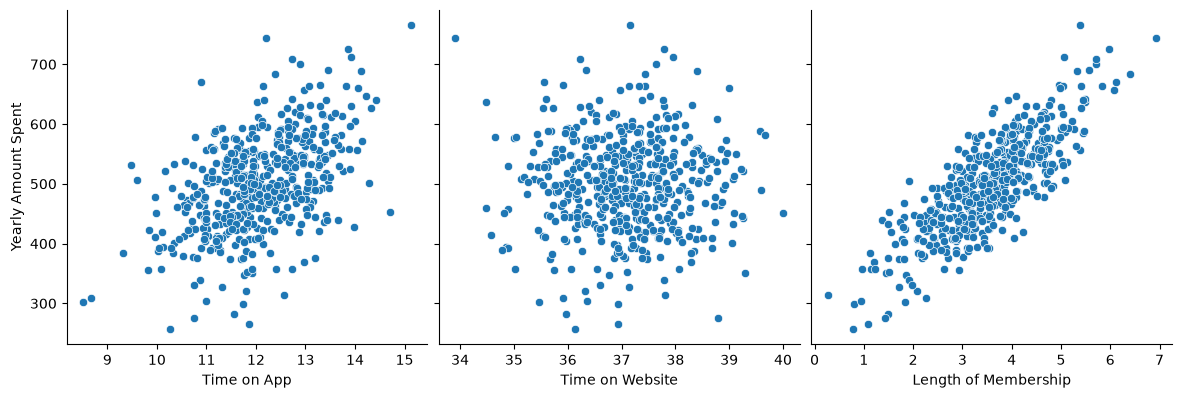

In [5]:
# Hubungan variabel bebas dengan variabel target
sns.pairplot(
    data,
    x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
    y_vars='Yearly Amount Spent',
    height=4, aspect=1, kind='scatter'
)
plt.show()


Scatter plot menunjukkan hubungan masing-masing variabel bebas dengan target. Heatmap berikut menghitung korelasi hanya pada kolom numerik; kolom teks seperti Email, Address, dan Avatar tidak disertakan.


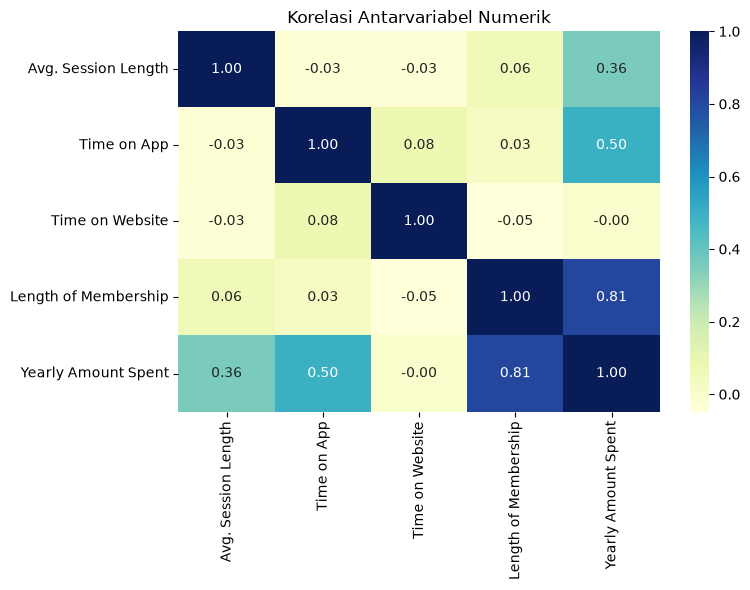

In [6]:
# Korelasi hanya dapat dihitung untuk kolom numerik.
numeric_data = data.select_dtypes(include=[np.number])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_data.corr(), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Korelasi Antarvariabel Numerik')
plt.tight_layout()
plt.show()


dari bentuk visualisasi di atas terlihat bahwa Length of Membership memiliki korelasi yang paling kuat terhadap Yearly Amount Spent

### Regresi Linier

In [7]:
# Pilih variabel bebas berdasarkan hasil analisis korelasi.
X = data['Length of Membership']
y = data['Yearly Amount Spent']

X.head()


0    4.082621
1    2.664034
2    4.104543
3    3.120179
4    4.446308
Name: Length of Membership, dtype: float64

In [8]:
# Pisahkan data latih (70%) dan data uji (30%).
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)


In [9]:
# Tampilkan ukuran pembagian data dan contoh data latih.
print(f'Data latih: {len(X_train)} baris')
print(f'Data uji: {len(X_test)} baris')
pd.concat([X_train, y_train], axis=1).head()


Data latih: 350 baris
Data uji: 150 baris


,Length of Membership,Yearly Amount Spent
153,6.076654,657.019924
84,4.396652,533.514935
310,3.363411,479.614812
494,2.768852,510.661792
126,4.106055,516.831557


In [10]:
# training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

In [11]:
# Latih model regresi linier dengan intercept.
lr = sm.OLS(y_train, X_train_sm).fit()
lr.params


const                   265.248299
Length of Membership     66.301522
dtype: float64

In [12]:
# analisis statistika dari garis regresi
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         08:27:43   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  265.2483      9.120     29.083      0.000     247.311     283.186
Length of Membership    66.3015      2.501     26.512      0.000      61.383      71.220
==============================================================================
Omnibus:                        1.643   Durbin-Watson:                   1.929
Prob(Omnibus):                  0.440   Jarque-Bera (JB):                1.471
Skew:                          -0.013   Prob(JB):                        0.479
Kurtosis:                       2.683   Cond. No.                         14.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

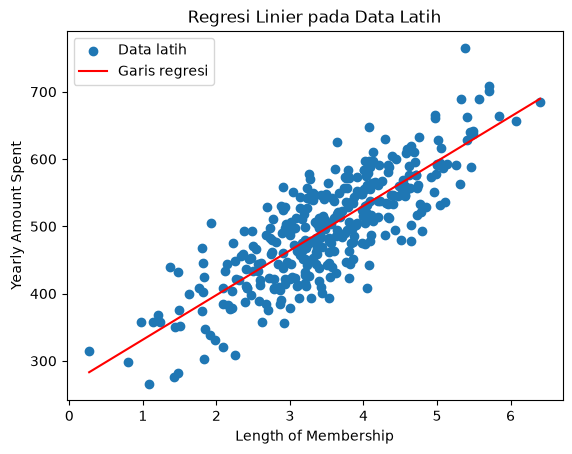

In [13]:
# Gunakan prediksi model, lalu urutkan X agar garis tergambar berurutan.
train_order = np.argsort(X_train.to_numpy())
y_train_line = lr.predict(X_train_sm)

plt.scatter(X_train, y_train, label='Data latih')
plt.plot(
    X_train.iloc[train_order], y_train_line.iloc[train_order],
    color='red', label='Garis regresi'
)
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Regresi Linier pada Data Latih')
plt.legend()
plt.show()


### Residual Analysis
dipakai untuk mengetahui tingkat error dari variabel yang dipengaruhi (y)

Error = Actual y value - y predicted value

In [14]:
# prediksi y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

res = (y_train - y_train_pred)

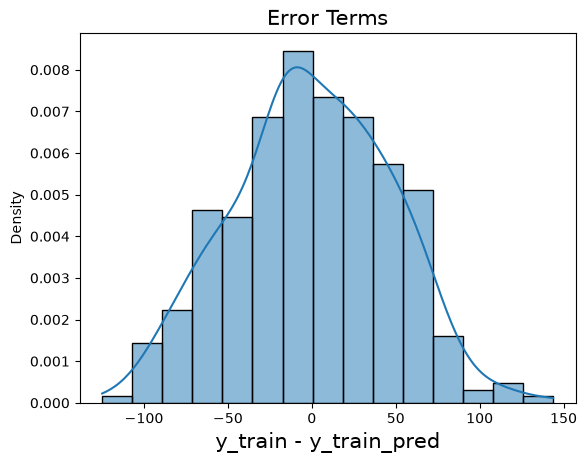

In [15]:
# Histogram dan kurva kepadatan untuk memeriksa distribusi residual.
plt.figure()
sns.histplot(res, bins=15, kde=True, stat='density')
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()


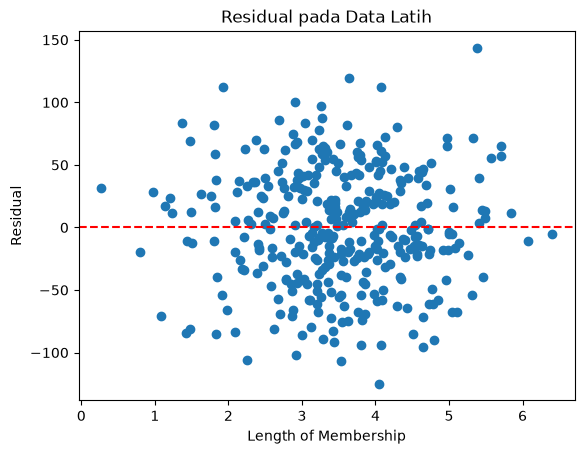

In [16]:
# Periksa pola residual terhadap variabel bebas.
plt.scatter(X_train, res)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.title('Residual pada Data Latih')
plt.show()


In [17]:
# prediksi pada data uji dan evaluasi model
X_test_sm = sm.add_constant(X_test)

# prediksi y value yang berkorelasi dengan X_test_sm
y_test_pred = lr.predict(X_test_sm)

# cetak 5 data terprediksi teratas
y_test_pred.head()

69     500.794385
29     579.688406
471    533.188991
344    446.066436
54     455.838449
dtype: float64

In [18]:
# Hitung dan tampilkan R-squared data latih dan data uji.
from sklearn.metrics import r2_score

r_squared_train = r2_score(y_train, y_train_pred)
r_squared = r2_score(y_test, y_test_pred)
print(f'R-squared data latih: {r_squared_train:.4f}')
print(f'R-squared data uji: {r_squared:.4f}')


R-squared data latih: 0.6688
R-squared data uji: 0.6119


Bandingkan nilai R-squared data latih dan data uji pada output di atas. R-squared menunjukkan proporsi variasi Yearly Amount Spent yang dijelaskan model dengan Length of Membership. Selisih kedua nilai membantu menilai apakah kinerja pada data uji mendekati kinerja pada data latih.


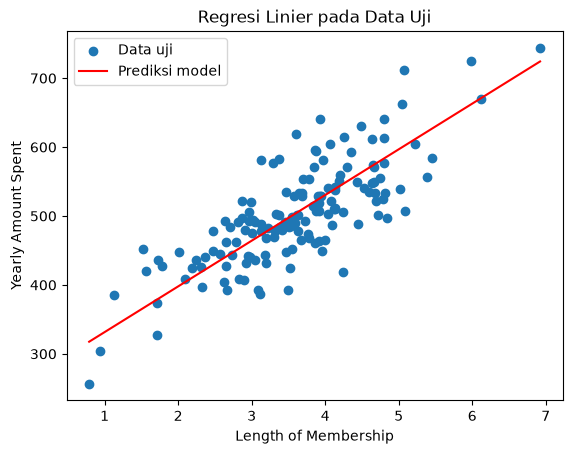

In [19]:
# Visualisasi data uji dan prediksi model dengan X yang terurut.
test_order = np.argsort(X_test.to_numpy())

plt.scatter(X_test, y_test, label='Data uji')
plt.plot(
    X_test.iloc[test_order], y_test_pred.iloc[test_order],
    color='red', label='Prediksi model'
)
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Regresi Linier pada Data Uji')
plt.legend()
plt.show()
